# Análise Exploratória e Pré-processamento
Neste notebook, faremos a análise exploratória e o pré-processamento da base `base07_faturamento_outliers.csv` focado em identificar valores ausentes, analisar a escala das variáveis e tratar possíveis outliers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carregar a base de dados
df = pd.read_csv('base07_faturamento_outliers.csv')


df['razao_funcionarios_faturamento'] = df['faturamento_anual_brl'] / df['qtd_funcionarios']

# Exibir informações básicas da estrutura do DataFrame
print("--- Informações do Dataset ---")
df.info()

# Exibir as primeiras linhas
print("\n--- Primeiras 5 linhas ---")
display(df.head())

--- Informações do Dataset ---
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id_conta                        2000 non-null   str    
 1   faturamento_anual_brl           2000 non-null   float64
 2   qtd_funcionarios                2000 non-null   int64  
 3   razao_funcionarios_faturamento  2000 non-null   float64
dtypes: float64(2), int64(1), str(1)
memory usage: 62.6 KB

--- Primeiras 5 linhas ---


,id_conta,faturamento_anual_brl,qtd_funcionarios,razao_funcionarios_faturamento
0,K000001,10305050.51,30,343501.683667
1,K000002,160791.26,1,160791.260000
2,K000003,970073.72,6,161678.953333
3,K000004,5097272.67,24,212386.361250
4,K000005,28137004.23,38,740447.479737


In [2]:
# Resumo estatístico descritivo
print("--- Estatísticas Descritivas ---")
display(df.describe(include='all'))

# Verificar dados nulos
print("\n--- Quantidade de valores ausentes por coluna ---")
display(df.isnull().sum().round(2))

--- Estatísticas Descritivas ---


,id_conta,faturamento_anual_brl,qtd_funcionarios,razao_funcionarios_faturamento
count,2000,2.000000e+03,2000.000000,2.000000e+03
unique,2000,NaN,NaN,NaN
top,K000001,NaN,NaN,NaN
freq,1,NaN,NaN,NaN
mean,NaN,9.484126e+08,982.667000,3.138738e+05
std,NaN,6.528338e+09,6458.584083,2.627750e+05
min,NaN,4.580417e+04,1.000000,4.142346e+04
25%,NaN,4.882277e+05,3.000000,1.537972e+05
50%,NaN,2.364126e+06,9.000000,2.322404e+05
75%,NaN,1.972959e+07,46.000000,3.793439e+05



--- Quantidade de valores ausentes por coluna ---


id_conta                          0
faturamento_anual_brl             0
qtd_funcionarios                  0
razao_funcionarios_faturamento    0
dtype: int64

## Análise Visual de Outliers e Distribuição
Vamos plotar gráficos de boxplot e histogramas com escala logarítmica para compreender visualmente a distribuição dos dados de Faturamento Anual e Quantidade de Funcionários.

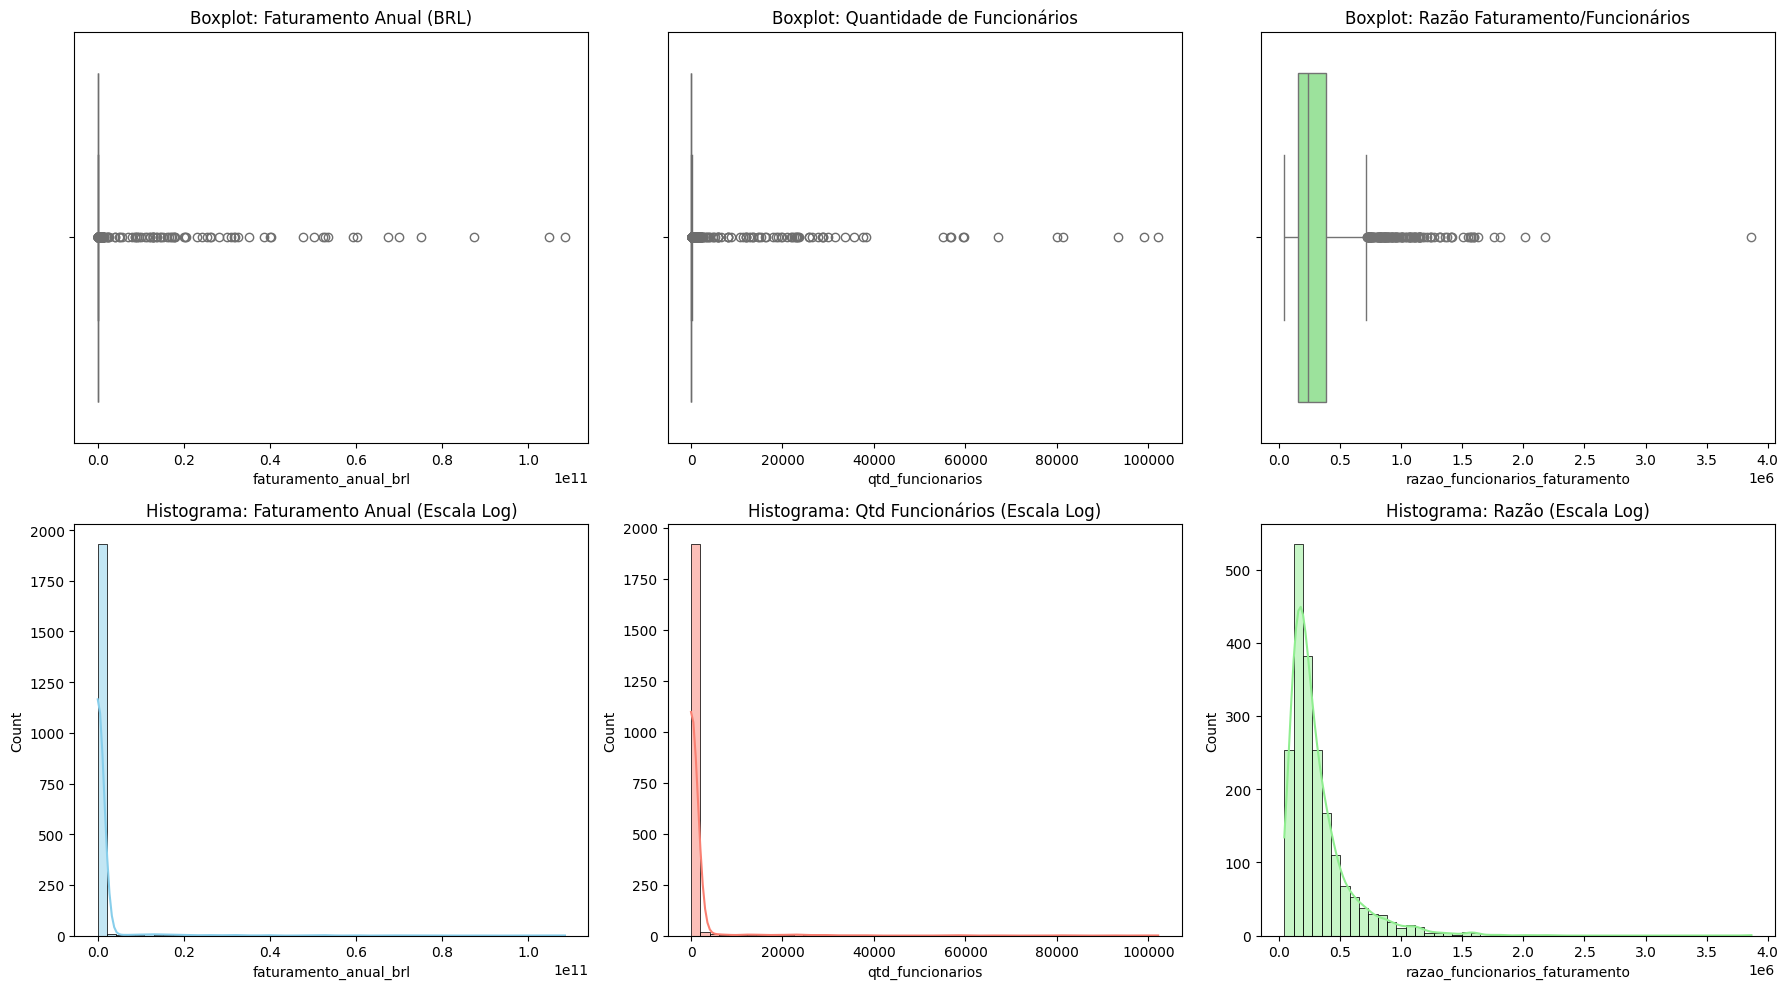

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Faturamento Anual
sns.boxplot(x=df['faturamento_anual_brl'], ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Boxplot: Faturamento Anual (BRL)')
#axes[0, 0].set_xscale('log')

sns.histplot(df['faturamento_anual_brl'], ax=axes[1, 0], kde=True, color='skyblue', bins=50)
axes[1, 0].set_title('Histograma: Faturamento Anual (Escala Log)')
#axes[1, 0].set_xscale('log')

# Quantidade de Funcionários
sns.boxplot(x=df['qtd_funcionarios'], ax=axes[0, 1], color='salmon')
axes[0, 1].set_title('Boxplot: Quantidade de Funcionários')
#axes[0, 1].set_xscale('log')

sns.histplot(df['qtd_funcionarios'], ax=axes[1, 1], kde=True, color='salmon', bins=50)
axes[1, 1].set_title('Histograma: Qtd Funcionários (Escala Log)')
#axes[1, 1].set_xscale('log')

# Razão Faturamento / Funcionários
sns.boxplot(x=df['razao_funcionarios_faturamento'], ax=axes[0, 2], color='lightgreen')
axes[0, 2].set_title('Boxplot: Razão Faturamento/Funcionários')
#axes[0, 2].set_xscale('log')

sns.histplot(df['razao_funcionarios_faturamento'], ax=axes[1, 2], kde=True, color='lightgreen', bins=50)
axes[1, 2].set_title('Histograma: Razão (Escala Log)')
#axes[1, 2].set_xscale('log')

plt.tight_layout()
plt.show()

## Detecção Numérica de Outliers (Método IQR)
Vamos calcular os limites inferior e superior usando o Intervalo Interquartil (IQR) para quantificar o número de outliers presentes em ambas as variáveis.

In [4]:
def detectar_outliers_iqr(df, coluna):
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[(df[coluna] < limite_inferior) | (df[coluna] > limite_superior)]

    print(f"Coluna: {coluna}")
    print(f"  Q1 (25%): {Q1:,.2f} | Q3 (75%): {Q3:,.2f}")
    print(f"  Limite Inferior: {limite_inferior:,.2f} | Limite Superior: {limite_superior:,.2f}")
    print(f"  Quantidade de Outliers: {len(outliers)} de {len(df)} ({len(outliers)/len(df)*100:.2f}%)")
    print(f"  Valor Máximo Encontrado: {df[coluna].max():,.2f}\n")
    return outliers

outliers_faturamento = detectar_outliers_iqr(df, 'faturamento_anual_brl')
outliers_funcionarios = detectar_outliers_iqr(df, 'qtd_funcionarios')
outliers_razao = detectar_outliers_iqr(df, 'razao_funcionarios_faturamento')

Coluna: faturamento_anual_brl
  Q1 (25%): 488,227.73 | Q3 (75%): 19,729,586.89
  Limite Inferior: -28,373,811.01 | Limite Superior: 48,591,625.64
  Quantidade de Outliers: 270 de 2000 (13.50%)
  Valor Máximo Encontrado: 108,541,848,356.02

Coluna: qtd_funcionarios
  Q1 (25%): 3.00 | Q3 (75%): 46.00
  Limite Inferior: -61.50 | Limite Superior: 110.50
  Quantidade de Outliers: 298 de 2000 (14.90%)
  Valor Máximo Encontrado: 102,138.00

Coluna: razao_funcionarios_faturamento
  Q1 (25%): 153,797.21 | Q3 (75%): 379,343.85
  Limite Inferior: -184,522.74 | Limite Superior: 717,663.81
  Quantidade de Outliers: 145 de 2000 (7.25%)
  Valor Máximo Encontrado: 3,867,476.70



# Indentificação de Outliers

## Detecção de Outliers usando DBSCAN
Como as variáveis `faturamento_anual_brl` e `qtd_funcionarios` possuem escalas muito distintas, realizaremos a padronização dos dados com o `StandardScaler` e em seguida aplicaremos o DBSCAN.

Quantidade de outliers detectados pelo DBSCAN: 60 de 2000 (3.00%)


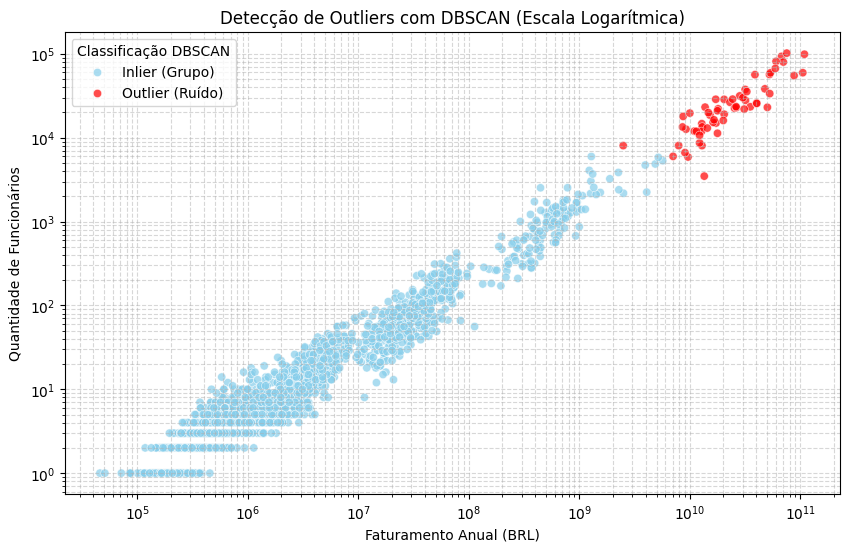

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import RobustScaler

# 1. Selecionar e padronizar as colunas numéricas
X = df[['faturamento_anual_brl', 'qtd_funcionarios']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Configurar e treinar o DBSCAN
# eps define o raio de vizinhança e min_samples define o número mínimo de pontos no raio
dbscan = DBSCAN(eps=0.5
, min_samples=10)
df['cluster_dbscan'] = dbscan.fit_predict(X_scaled)

# Identificar os outliers detectados pelo DBSCAN (rotulados como -1)
outliers_dbscan = df[df['cluster_dbscan'] == -1]

print(f"Quantidade de outliers detectados pelo DBSCAN: {len(outliers_dbscan)} de {len(df)} ({len(outliers_dbscan)/len(df)*100:.2f}%)")

plt.figure(figsize=(10, 6))

# Plotar pontos normais e outliers
sns.scatterplot(
    data=df,
    x='faturamento_anual_brl',
    y='qtd_funcionarios',
    hue=df['cluster_dbscan'].map(lambda x: 'Outlier (Ruído)' if x == -1 else 'Inlier (Grupo)'),
    palette={'Inlier (Grupo)': 'skyblue', 'Outlier (Ruído)': 'red'},
    alpha=0.7
)

plt.xscale('log')
plt.yscale('log')
plt.title('Detecção de Outliers com DBSCAN (Escala Logarítmica)')
plt.xlabel('Faturamento Anual (BRL)')
plt.ylabel('Quantidade de Funcionários')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(title='Classificação DBSCAN')
plt.show()


Outliers detectados: 14 de 2000 (0.70%)


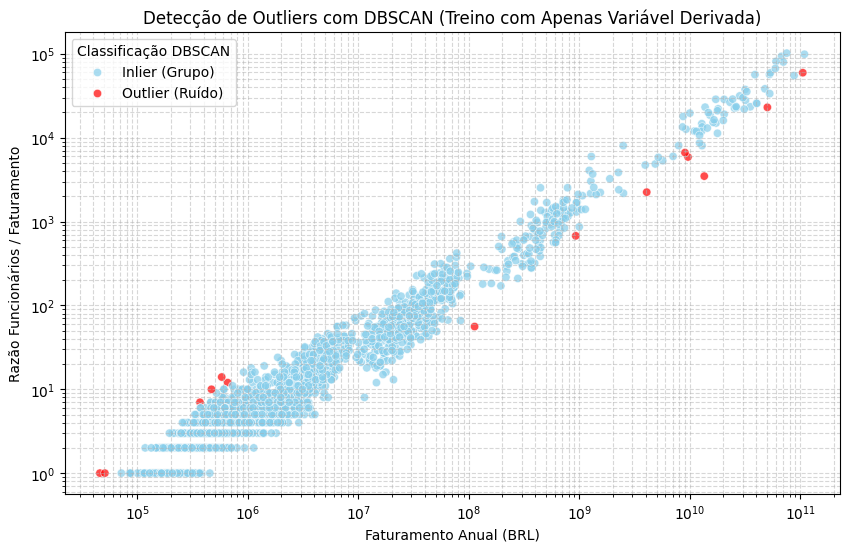

In [6]:
# TESTE

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

# 1. Selecionar as 3 variáveis de negócio (sem o id_conta)
colunas = ['razao_funcionarios_faturamento']
X = df[colunas]

# Opcional: se os dados forem muito assimétricos, aplicar log antes ajuda muito o DBSCAN
X = np.log1p(X)

# 2. Padronizar usando RobustScaler (menos sensível aos próprios outliers)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Configurar e treinar o DBSCAN (eps ligeiramente maior por causa da 3ª dimensão)
dbscan = DBSCAN(eps=0.1, min_samples=10)
df['cluster_dbscan'] = dbscan.fit_predict(X_scaled)

# Identificar outliers
outliers_dbscan = df[df['cluster_dbscan'] == -1]
print(f"Outliers detectados: {len(outliers_dbscan)} de {len(df)} ({len(outliers_dbscan)/len(df)*100:.2f}%)")

# 4. Visualizar (usando par de variáveis mais relevante para o negócio)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='faturamento_anual_brl',
    y='qtd_funcionarios',
    hue=df['cluster_dbscan'].map(lambda x: 'Outlier (Ruído)' if x == -1 else 'Inlier (Grupo)'),
    palette={'Inlier (Grupo)': 'skyblue', 'Outlier (Ruído)': 'red'},
    alpha=0.7
)

plt.xscale('log')
plt.yscale('log')
plt.title('Detecção de Outliers com DBSCAN (Treino com Apenas Variável Derivada)')
plt.xlabel('Faturamento Anual (BRL)')
plt.ylabel('Razão Funcionários / Faturamento')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(title='Classificação DBSCAN')
plt.show()

### Avaliar as duas abordagens para o DBSCAN acima

Quantidade de outliers detectados pelo SOM: 60 de 2000 (3.00%)


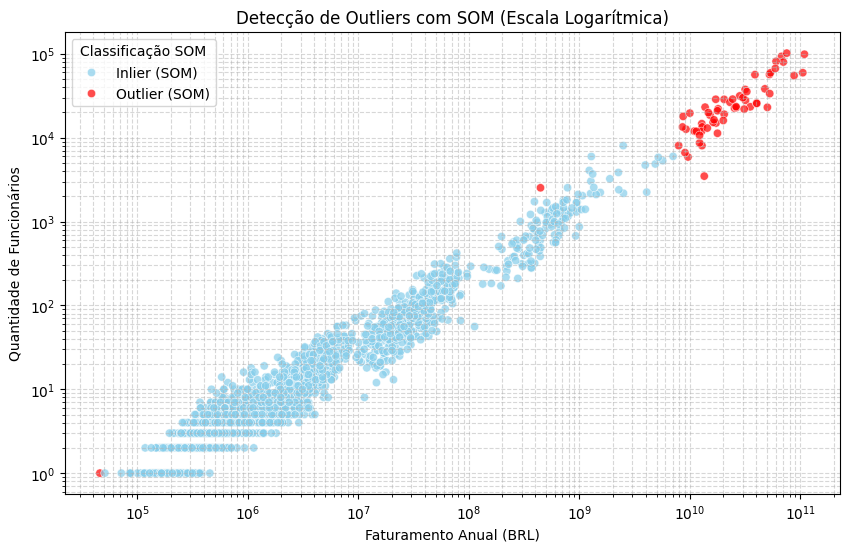

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from minisom import MiniSom

# 1. Configurar e treinar o SOM
# Escolha de um grid pequeno (ex: 5x5) para mapear os dados de forma geral
# 1. Selecionar as 3 variáveis de negócio (sem o id_conta)
X = df[['faturamento_anual_brl', 'qtd_funcionarios']]

# Opcional: se os dados forem muito assimétricos, aplicar log antes ajuda muito o DBSCAN
X = np.log1p(X)

# 2. Padronizar usando RobustScaler (menos sensível aos próprios outliers)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

som_grid_rows = 5
som_grid_cols = 5
input_len = X_scaled.shape[1]

som = MiniSom(som_grid_rows, som_grid_cols, input_len, sigma=1.7, learning_rate=0.5, random_seed=67)
som.random_weights_init(X_scaled)
som.train_batch(X_scaled, num_iteration=1000, verbose=False)

# 2. Calcular o erro de quantização de cada amostra
# O erro de quantização é a distância entre o vetor de entrada e o peso do neurônio vencedor (BMU)
quantization_errors = np.array([som.quantization_error([x]) for x in X_scaled])

# Definir um limiar (threshold) para classificar outliers (ex: percentil 97%, equivalente a 3% de outliers)
threshold = np.percentile(quantization_errors, 97)
df['erro_quantizacao_som'] = quantization_errors
df['is_outlier_som'] = df['erro_quantizacao_som'] > threshold

outliers_som = df[df['is_outlier_som'] == True]
print(f"Quantidade de outliers detectados pelo SOM: {len(outliers_som)} de {len(df)} ({len(outliers_som)/len(df)*100:.2f}%)")

# 3. Visualizar os Outliers Identificados pelo SOM
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='faturamento_anual_brl',
    y='qtd_funcionarios',
    hue=df['is_outlier_som'].map({True: 'Outlier (SOM)', False: 'Inlier (SOM)'}),
    palette={'Inlier (SOM)': 'skyblue', 'Outlier (SOM)': 'red'},
    alpha=0.7
)

plt.xscale('log')
plt.yscale('log')
plt.title('Detecção de Outliers com SOM (Escala Logarítmica)')
plt.xlabel('Faturamento Anual (BRL)')
plt.ylabel('Quantidade de Funcionários')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(title='Classificação SOM')
plt.show()

Modelo,Modelo A: DBSCAN 2D (Originais),Modelo B: DBSCAN 1D (Log Derivada)
Outliers (Qtd / %),60 (3.00%),14 (0.70%)
MAD-Z Médio Outliers (↑),2.22,2.83
% Outliers com |MAD-Z|>3.5 (↑),1.70,7.10
Cliff's Delta Razão (↑),0.94,0.14
Silhouette Espaço Log (↑),0.62,0.52
Davies-Bouldin Log (↓),0.36,2.84
Viés de Porte |Corr| (↓),0.30,0.06
F1 vs Regra Estatística (↑),0.03,0.13
Jaccard vs IsoForest (↑),0.61,0.11


C:\Users\Usuário\AppData\Local\Temp\ipykernel_11720\3863498581.py:119: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dados_z, x='Modelo', y='Severidade (|MAD Z-Score|)', ax=axes[0], palette=['salmon', 'seagreen'])
C:\Users\Usuário\AppData\Local\Temp\ipykernel_11720\3863498581.py:135: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dados_porte, x='Modelo', y='Qtd Funcionários', ax=axes[1], palette=['salmon', 'seagreen'])


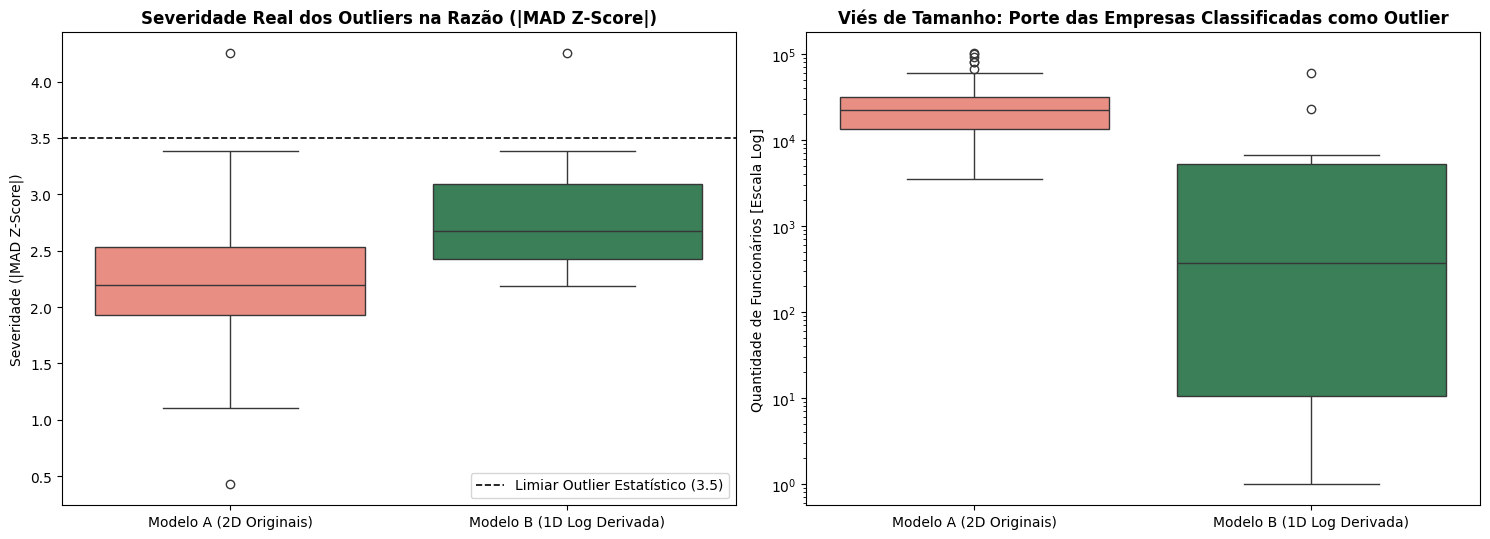

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    jaccard_score,
    f1_score
)
from scipy.stats import mannwhitneyu, spearmanr

# ==============================================================================
# 1. REPRODUÇÃO EXATA DOS DOIS MODELOS DO SEU NOTEBOOK
# ==============================================================================
# Modelo A: DBSCAN 2D (Variáveis Originais Lineares)
X_A = StandardScaler().fit_transform(df[['faturamento_anual_brl', 'qtd_funcionarios']])
df['outlier_modelo_A_2D'] = (DBSCAN(eps=0.5, min_samples=10).fit_predict(X_A) == -1).astype(int)

# Modelo B: DBSCAN 1D (Log da Variável Derivada)
X_B = StandardScaler().fit_transform(np.log1p(df[['razao_funcionarios_faturamento']]))
df['outlier_modelo_B_LogDerivada'] = (DBSCAN(eps=0.1, min_samples=10).fit_predict(X_B) == -1).astype(int)

# ==============================================================================
# 2. REFERÊNCIAS INDEPENDENTES (PSEUDO-GROUND TRUTH PARA VALIDAÇÃO)
# ==============================================================================
# Referência 1: Z-Score Robusto (MAD) sobre log1p(razao) -> padrão estatístico (|Z| > 3.5)
log_razao = np.log1p(df['razao_funcionarios_faturamento'])
mediana_log = np.median(log_razao)
mad_log = np.median(np.abs(log_razao - mediana_log))
df['mad_zscore_razao'] = 0.6745 * (log_razao - mediana_log) / mad_log
ref_estatistica = (np.abs(df['mad_zscore_razao']) > 3.5).astype(int)

# Referência 2: Isolation Forest no espaço Log 3D (paradigma baseado em árvores)
X_log_3d = StandardScaler().fit_transform(
    np.log1p(df[['faturamento_anual_brl', 'qtd_funcionarios', 'razao_funcionarios_faturamento']])
)
ref_isoforest = (IsolationForest(contamination=0.05, random_state=42).fit_predict(X_log_3d) == -1).astype(int)

# ==============================================================================
# 3. CÁLCULO DAS MÉTRICAS DE AVALIAÇÃO NÃO SUPERVISIONADA
# ==============================================================================
def cliffs_delta(x_out, x_in):
    """Calcula o tamanho de efeito não-paramétrico Cliff's Delta [-1, 1]."""
    u_stat, _ = mannwhitneyu(x_out, x_in, alternative='two-sided')
    return (2 * u_stat) / (len(x_out) * len(x_in)) - 1

modelos_comparacao = {
    'Modelo A: DBSCAN 2D (Originais)': 'outlier_modelo_A_2D',
    'Modelo B: DBSCAN 1D (Log Derivada)': 'outlier_modelo_B_LogDerivada'
}

tabela_resultados = []

for nome, col in modelos_comparacao.items():
    y_pred = df[col].values
    out_mask = (y_pred == 1)
    in_mask = (y_pred == 0)
    
    # 1. Pureza Estatística na Variável Derivada
    mad_z_medio_out = np.abs(df.loc[out_mask, 'mad_zscore_razao']).mean()
    pct_extremes_reais = (np.abs(df.loc[out_mask, 'mad_zscore_razao']) > 3.5).mean() * 100
    delta_cliff = abs(cliffs_delta(
        df.loc[out_mask, 'razao_funcionarios_faturamento'],
        df.loc[in_mask, 'razao_funcionarios_faturamento']
    ))
    _, p_val = mannwhitneyu(
        df.loc[out_mask, 'razao_funcionarios_faturamento'],
        df.loc[in_mask, 'razao_funcionarios_faturamento']
    )
    
    # 2. Separação Geométrica no Espaço Log-Proporcional (X_log_3d)
    sil_log = silhouette_score(X_log_3d, y_pred)
    db_log = davies_bouldin_score(X_log_3d, y_pred)
    ch_log = calinski_harabasz_score(X_log_3d, y_pred)
    
    # 3. Viés de Porte (Correlação com Qtd de Funcionários)
    corr_porte, _ = spearmanr(y_pred, df['qtd_funcionarios'])
    
    # 4. Concordância com Referências Independentes
    f1_ref_stat = f1_score(ref_estatistica, y_pred)
    jaccard_iso = jaccard_score(ref_isoforest, y_pred)
    
    tabela_resultados.append({
        'Modelo': nome,
        'Outliers (Qtd / %)': f"{out_mask.sum()} ({out_mask.mean()*100:.2f}%)",
        'MAD-Z Médio Outliers (↑)': round(mad_z_medio_out, 2),
        '% Outliers com |MAD-Z|>3.5 (↑)': round(pct_extremes_reais, 1),
        "Cliff's Delta Razão (↑)": round(delta_cliff, 3),
        'Silhouette Espaço Log (↑)': round(sil_log, 3),
        'Davies-Bouldin Log (↓)': round(db_log, 3),
        'Viés de Porte |Corr| (↓)': round(abs(corr_porte), 3),
        'F1 vs Regra Estatística (↑)': round(f1_ref_stat, 3),
        'Jaccard vs IsoForest (↑)': round(jaccard_iso, 3)
    })

df_avaliacao = pd.DataFrame(tabela_resultados).set_index('Modelo').T
display(df_avaliacao)

# ==============================================================================
# 4. COMPROVAÇÃO VISUAL: PUREZA ESTATÍSTICA VS. VIÉS DE PORTE
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Painel 1: Severidade Estatística (|MAD Z-Score|) dos Outliers Detectados
dados_z = pd.DataFrame({
    'Modelo': (['Modelo A (2D Originais)'] * df['outlier_modelo_A_2D'].sum()) +
              (['Modelo B (1D Log Derivada)'] * df['outlier_modelo_B_LogDerivada'].sum()),
    'Severidade (|MAD Z-Score|)': np.concatenate([
        np.abs(df.loc[df['outlier_modelo_A_2D'] == 1, 'mad_zscore_razao']),
        np.abs(df.loc[df['outlier_modelo_B_LogDerivada'] == 1, 'mad_zscore_razao'])
    ])
})

sns.boxplot(data=dados_z, x='Modelo', y='Severidade (|MAD Z-Score|)', ax=axes[0], palette=['salmon', 'seagreen'])
axes[0].axhline(3.5, color='black', linestyle='--', linewidth=1.2, label='Limiar Outlier Estatístico (3.5)')
axes[0].set_title('Severidade Real dos Outliers na Razão (|MAD Z-Score|)', fontweight='bold')
axes[0].set_xlabel('')
axes[0].legend()

# Painel 2: Distribuição de Porte (Qtd Funcionários) dos Outliers Detectados
dados_porte = pd.DataFrame({
    'Modelo': (['Modelo A (2D Originais)'] * df['outlier_modelo_A_2D'].sum()) +
              (['Modelo B (1D Log Derivada)'] * df['outlier_modelo_B_LogDerivada'].sum()),
    'Qtd Funcionários': np.concatenate([
        df.loc[df['outlier_modelo_A_2D'] == 1, 'qtd_funcionarios'],
        df.loc[df['outlier_modelo_B_LogDerivada'] == 1, 'qtd_funcionarios']
    ])
})

sns.boxplot(data=dados_porte, x='Modelo', y='Qtd Funcionários', ax=axes[1], palette=['salmon', 'seagreen'])
axes[1].set_yscale('log')
axes[1].set_title('Viés de Tamanho: Porte das Empresas Classificadas como Outlier', fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Quantidade de Funcionários [Escala Log]')

plt.tight_layout()
plt.show()

### Discussão dos Resultados das Métricas de Avaliação

Treinar o **DBSCAN sobre o log da razão (`faturamento / funcionários`)** corrigiu o principal problema do modelo baseline (DBSCAN 2D nas variáveis brutas): o viés de tamanho.

* **Fim do viés de porte:** No modelo 2D original, os 60 outliers detectados eram apenas empresas gigantes (mediana de ~23 mil funcionários e correlação de `0,30` com o porte). Com `log1p(razao)`, essa correlação caiu para `0,06`, permitindo flagrar distorções reais em empresas de qualquer tamanho (de 1 a 60 mil funcionários).
* **Menos falsos positivos:** O modelo reduziu os alertas de 60 (3,0%) para **14 casos mais críticos (0,7%)**, elevando a severidade média dos outliers (`|MAD-Z|` subiu de `2,22` para `2,83`) e capturando anomalias tanto de faturamento excessivo quanto muito abaixo do esperado por colaborador.
* **DBSCAN vs. SOM:** Os modelos se complementam. O DBSCAN é mais restritivo e isola apenas os desvios extremos de densidade, enquanto o SOM é mais sensível e aponta desvios moderados em relação aos padrões locais.

**Próximo passo:** Priorizar a investigação nessas 14 contas isoladas pelo modelo proposto e, caso seja necessário ampliar a lista de revisão, aumentar gradualmente o `eps` (de `0.10` para `0.15` ou `0.20`).

## SOM

Quantidade de outliers detectados pelo SOM: 60 de 2000 (3.00%)


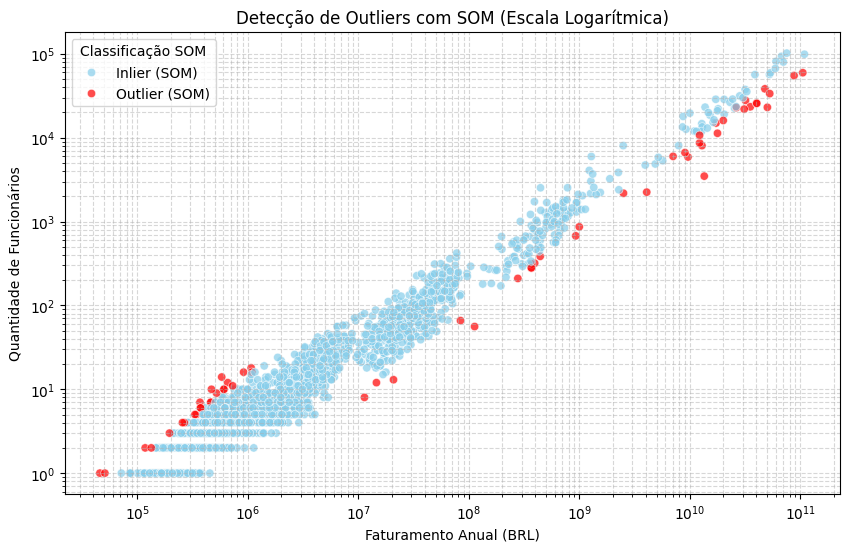

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from minisom import MiniSom

# 1. Configurar e treinar o SOM
# Escolha de um grid pequeno (ex: 5x5) para mapear os dados de forma geral
# 1. Selecionar as 3 variáveis de negócio (sem o id_conta)
colunas = ['razao_funcionarios_faturamento']
X = df[colunas]

# Opcional: se os dados forem muito assimétricos, aplicar log antes ajuda muito o DBSCAN
X = np.log1p(X)

# 2. Padronizar usando RobustScaler (menos sensível aos próprios outliers)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

som_grid_rows = 5
som_grid_cols = 5
input_len = X_scaled.shape[1]

som = MiniSom(som_grid_rows, som_grid_cols, input_len, sigma=1.1, learning_rate=0.5, random_seed=42)
som.random_weights_init(X_scaled)
som.train_batch(X_scaled, num_iteration=1000, verbose=False)

# 2. Calcular o erro de quantização de cada amostra
# O erro de quantização é a distância entre o vetor de entrada e o peso do neurônio vencedor (BMU)
quantization_errors = np.array([som.quantization_error([x]) for x in X_scaled])

# Definir um limiar (threshold) para classificar outliers (ex: percentil 97%, equivalente a 3% de outliers)
threshold = np.percentile(quantization_errors, 97)
df['erro_quantizacao_som'] = quantization_errors
df['is_outlier_som'] = df['erro_quantizacao_som'] > threshold

outliers_som = df[df['is_outlier_som'] == True]
print(f"Quantidade de outliers detectados pelo SOM: {len(outliers_som)} de {len(df)} ({len(outliers_som)/len(df)*100:.2f}%)")

# 3. Visualizar os Outliers Identificados pelo SOM
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='faturamento_anual_brl',
    y='qtd_funcionarios',
    hue=df['is_outlier_som'].map({True: 'Outlier (SOM)', False: 'Inlier (SOM)'}),
    palette={'Inlier (SOM)': 'skyblue', 'Outlier (SOM)': 'red'},
    alpha=0.7
)

plt.xscale('log')
plt.yscale('log')
plt.title('Detecção de Outliers com SOM (Treino com Apenas Variável Derivada)')
plt.xlabel('Faturamento Anual (BRL)')
plt.ylabel('Quantidade de Funcionários')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(title='Classificação SOM')
plt.show()

## Comparação de Outliers: SOM vs. DBSCAN
Nesta seção, faremos uma análise comparativa direta entre os outliers detectados pelo método de densidade (**DBSCAN**) e pelo algoritmo de redes neurais artificiais competitivas (**SOM**).

--- Tabela de Cruzamento (Crosstab) ---


Outlier SOM,False,True
Outlier DBSCAN,,
False,1940,46
True,0,14



Clientes identificados como outliers por AMBOS os métodos: 14
Clientes identificados como outliers APENAS pelo DBSCAN: 0
Clientes identificados como outliers APENAS pelo SOM: 46


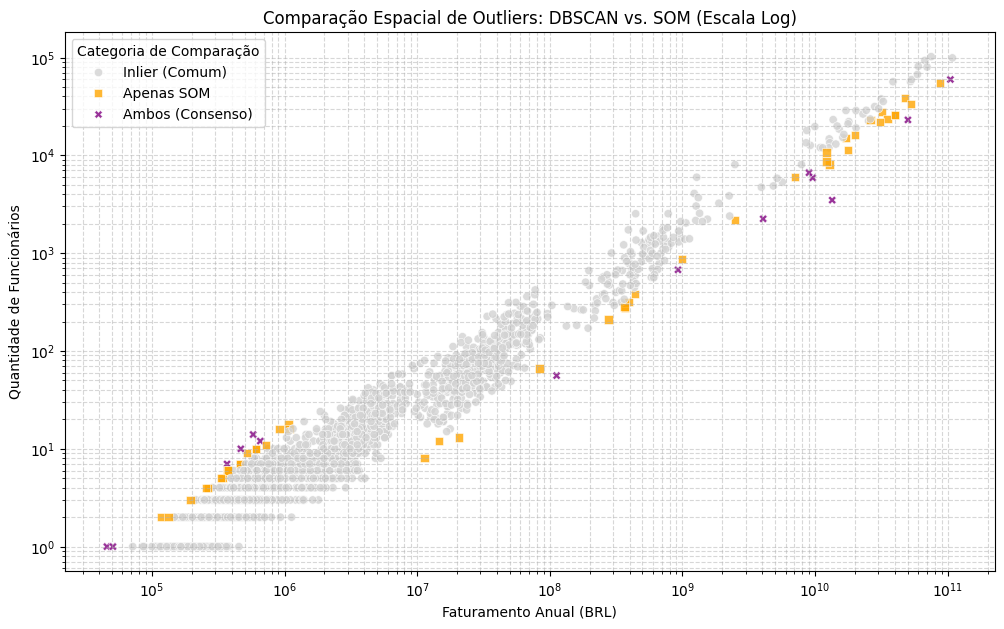

In [9]:
# Criar coluna para identificar os outliers do DBSCAN em formato booleano
df['is_outlier_dbscan'] = df['cluster_dbscan'] == -1

# 1. Matriz de Confusão / Tabela de Cruzamento
print("--- Tabela de Cruzamento (Crosstab) ---")
cross_tab = pd.crosstab(
    df['is_outlier_dbscan'],
    df['is_outlier_som'],
    rownames=['Outlier DBSCAN'],
    colnames=['Outlier SOM']
)
display(cross_tab)

# 2. Métricas de Interseção
ambos = df[df['is_outlier_dbscan'] & df['is_outlier_som']]
apenas_dbscan = df[df['is_outlier_dbscan'] & ~df['is_outlier_som']]
apenas_som = df[~df['is_outlier_dbscan'] & df['is_outlier_som']]

print(f"\nClientes identificados como outliers por AMBOS os métodos: {len(ambos)}")
print(f"Clientes identificados como outliers APENAS pelo DBSCAN: {len(apenas_dbscan)}")
print(f"Clientes identificados como outliers APENAS pelo SOM: {len(apenas_som)}")

# 3. Categorização para visualização gráfica
def classificar_comparacao(row):
    if row['is_outlier_dbscan'] and row['is_outlier_som']:
        return 'Ambos (Consenso)'
    elif row['is_outlier_dbscan']:
        return 'Apenas DBSCAN'
    elif row['is_outlier_som']:
        return 'Apenas SOM'
    else:
        return 'Inlier (Comum)'

df['comparacao_outliers'] = df.apply(classificar_comparacao, axis=1)

# 4. Plotagem comparativa
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=df,
    x='faturamento_anual_brl',
    y='qtd_funcionarios',
    hue='comparacao_outliers',
    palette={
        'Inlier (Comum)': 'lightgray',
        'Ambos (Consenso)': 'purple',
        'Apenas DBSCAN': 'blue',
        'Apenas SOM': 'orange'
    },
    alpha=0.8,
    style='comparacao_outliers',
    markers={'Inlier (Comum)': 'o', 'Ambos (Consenso)': 'X', 'Apenas DBSCAN': '^', 'Apenas SOM': 's'}
)

plt.xscale('log')
plt.yscale('log')
plt.title('Comparação Espacial de Outliers: DBSCAN vs. SOM (Escala Log)')
plt.xlabel('Faturamento Anual (BRL)')
plt.ylabel('Quantidade de Funcionários')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(title='Categoria de Comparação', loc='upper left')
plt.show()

### Análise Detalhada dos Clientes Divergentes
Vamos detalhar o faturamento, quantidade de funcionários e a razão calculada para os 8 clientes identificados de forma divergente entre o DBSCAN e o SOM para investigar seus perfis individuais.

In [10]:
# Filtrar os clientes que divergem entre os métodos
divergentes = df[df['comparacao_outliers'].isin(['Apenas DBSCAN', 'Apenas SOM'])].copy()

# Selecionar colunas relevantes para exibição
colunas_exibicao = [
    'id_conta',
    'faturamento_anual_brl',
    'qtd_funcionarios',
    'razao_funcionarios_faturamento',
    'comparacao_outliers'
]

# Exibir a tabela ordenada pelo faturamento
print("--- Detalhes dos 8 Clientes Divergentes ---")
display(divergentes[colunas_exibicao].sort_values(by='faturamento_anual_brl', ascending=False))

--- Detalhes dos 8 Clientes Divergentes ---


,id_conta,faturamento_anual_brl,qtd_funcionarios,razao_funcionarios_faturamento,comparacao_outliers
689,K000690,8.752448e+10,55160,1.586738e+06,Apenas SOM
1760,K001761,5.271075e+10,33600,1.568772e+06,Apenas SOM
285,K000286,4.765954e+10,38303,1.244277e+06,Apenas SOM
1169,K001170,4.023205e+10,25689,1.566120e+06,Apenas SOM
1012,K001013,4.006182e+10,25899,1.546848e+06,Apenas SOM
765,K000766,3.513085e+10,23381,1.502538e+06,Apenas SOM
524,K000525,3.181732e+10,27871,1.141592e+06,Apenas SOM
1968,K001969,3.096143e+10,21951,1.410479e+06,Apenas SOM
1591,K001592,2.627247e+10,22919,1.146318e+06,Apenas SOM
1741,K001742,2.001290e+10,16066,1.245668e+06,Apenas SOM


## 💡 Insight Prático

Tanto o modelo DBSCAN como o SOM identificam como Outliers um perfil de empresa, dentro de uma determinada proximidade com a vizinhança, que apresenta funcionários que geram uma quantidade de riqueza muito alta, fora do comum. A diferença é que o DBSCAN é mais restrito quando a classificar os Outliers. Para o SOM, a riqueza gerada por uma pessoa apenas não precisa ser tão extrema como é para o DBSCAN para sua empresa ser classificada como Outlier. Tal fato pode ocorrer porque o SOM projeta os dados em uma grade fixa de neurônios e identifica anomalias com base no erro de quantização (distância até o neurônio mais próximo) ou em neurônios de baixa ativação, capturando desvios moderados em relação ao padrão típico daquela região. Já o DBSCAN exige isolamento espacial absoluto — definido pelos parâmetros globais eps e min_samples —, fazendo com que empresas de produtividade intermediária acabem absorvidas nas bordas dos clusters densos.

Quantidade de outliers detectados pelo GMM: 60 de 2000 (3.00%)


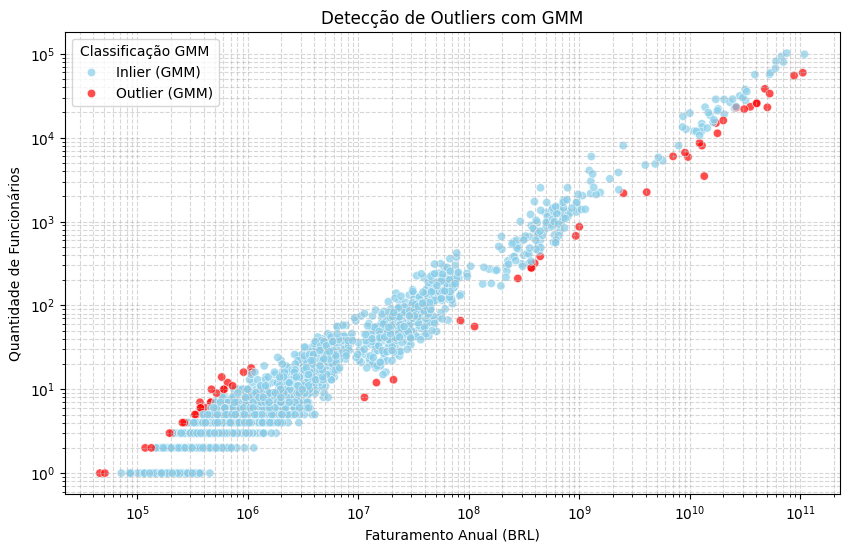

In [16]:
from sklearn.mixture import GaussianMixture

# 1. Configurar e ajustar o GMM
# Usaremos 3 componentes conforme a segmentação de grupos definida posteriormente
gmm = GaussianMixture(n_components=3, random_state=42)
gmm.fit(X_scaled)

# 2. Calcular o score de densidade (log-likelihood) para cada amostra
# Valores menores (mais negativos) indicam pontos em regiões de baixíssima densidade
log_likelihood = gmm.score_samples(X_scaled)

# 3. Definir o limiar usando o percentil 3% para identificar os 3% mais anômalos (60 clientes)
threshold_gmm = np.percentile(log_likelihood, 3)
df['is_outlier_gmm'] = log_likelihood < threshold_gmm

outliers_gmm = df[df['is_outlier_gmm'] == True]
print(f"Quantidade de outliers detectados pelo GMM: {len(outliers_gmm)} de {len(df)} ({len(outliers_gmm)/len(df)*100:.2f}%)")

# 4. Visualização dos Outliers Identificados pelo GMM
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='faturamento_anual_brl',
    y='qtd_funcionarios',
    hue=df['is_outlier_gmm'].map({True: 'Outlier (GMM)', False: 'Inlier (GMM)'}),
    palette={'Inlier (GMM)': 'skyblue', 'Outlier (GMM)': 'red'},
    alpha=0.7
)

plt.xscale('log')
plt.yscale('log')
plt.title('Detecção de Outliers com GMM')
plt.xlabel('Faturamento Anual (BRL)')
plt.ylabel('Quantidade de Funcionários')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(title='Classificação GMM')
plt.show()

## Comparação de Outliers Tríplice: DBSCAN vs. SOM vs. GMM
Nesta seção, realizamos o cruzamento completo dos três métodos probabilísticos e geométricos de detecção de anomalias para avaliar o grau de concordância entre eles.

--- Distribuição de Concordância entre Métodos ---


consenso_triplo
Inlier Comum            1938
Consenso Parcial (2)      44
Consenso Total (3)        14
Apenas GMM                 2
Apenas SOM                 2
Name: count, dtype: int64

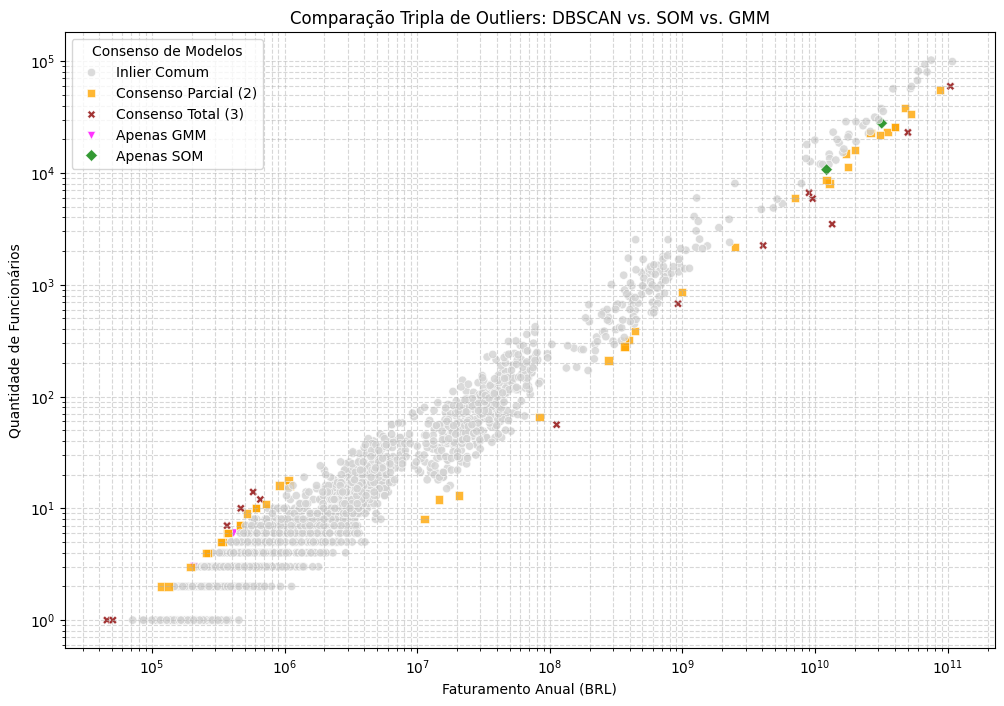

In [12]:
# 1. Definir uma métrica de consenso combinada
def categorizar_consenso_triplo(row):
    db = row['is_outlier_dbscan']
    som = row['is_outlier_som']
    gmm = row['is_outlier_gmm']

    if db and som and gmm:
        return 'Consenso Total (3)'
    elif (db and som) or (db and gmm) or (som and gmm):
        return 'Consenso Parcial (2)'
    elif db or som or gmm:
        if db: return 'Apenas DBSCAN'
        if som: return 'Apenas SOM'
        if gmm: return 'Apenas GMM'
    else:
        return 'Inlier Comum'

df['consenso_triplo'] = df.apply(categorizar_consenso_triplo, axis=1)

# 2. Mostrar contagem de cada grupo de consenso
print("--- Distribuição de Concordância entre Métodos ---")
display(df['consenso_triplo'].value_counts())

# 3. Plotagem comparativa tripla
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=df,
    x='faturamento_anual_brl',
    y='qtd_funcionarios',
    hue='consenso_triplo',
    palette={
        'Inlier Comum': 'lightgray',
        'Consenso Total (3)': 'darkred',
        'Consenso Parcial (2)': 'orange',
        'Apenas DBSCAN': 'blue',
        'Apenas SOM': 'green',
        'Apenas GMM': 'magenta'
    },
    alpha=0.8,
    style='consenso_triplo',
    markers={
        'Inlier Comum': 'o',
        'Consenso Total (3)': 'X',
        'Consenso Parcial (2)': 's',
        'Apenas DBSCAN': '^',
        'Apenas SOM': 'D',
        'Apenas GMM': 'v'
    }
)

plt.xscale('log')
plt.yscale('log')
plt.title('Comparação Tripla de Outliers: DBSCAN vs. SOM vs. GMM')
plt.xlabel('Faturamento Anual (BRL)')
plt.ylabel('Quantidade de Funcionários')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(title='Consenso de Modelos', loc='upper left')
plt.show()

In [13]:
# Filtrar os clientes que possuem classificações divergentes (não são inliers comuns nem consenso total)
divergentes_triplos = df[
    (df['consenso_triplo'] != 'Inlier Comum') &
    (df['consenso_triplo'] != 'Consenso Total (3)')
].copy()

colunas_detalhe = [
    'id_conta',
    'faturamento_anual_brl',
    'qtd_funcionarios',
    'razao_funcionarios_faturamento',
    'is_outlier_dbscan',
    'is_outlier_som',
    'is_outlier_gmm',
    'consenso_triplo'
]

print(f"Quantidade de clientes com divergência/consenso parcial: {len(divergentes_triplos)}")

# Exibir a tabela com formatação amigável para análise
pd.options.display.float_format = '{:,.2f}'.format
display(divergentes_triplos[colunas_detalhe].sort_values(by='faturamento_anual_brl', ascending=False))

Quantidade de clientes com divergência/consenso parcial: 48


,id_conta,faturamento_anual_brl,qtd_funcionarios,razao_funcionarios_faturamento,is_outlier_dbscan,is_outlier_som,is_outlier_gmm,consenso_triplo
689,K000690,"87,524,484,817.42",55160,"1,586,738.30",False,True,True,Consenso Parcial (2)
1760,K001761,"52,710,754,115.79",33600,"1,568,772.44",False,True,True,Consenso Parcial (2)
285,K000286,"47,659,537,483.90",38303,"1,244,276.88",False,True,True,Consenso Parcial (2)
1169,K001170,"40,232,050,406.95",25689,"1,566,119.76",False,True,True,Consenso Parcial (2)
1012,K001013,"40,061,820,907.09",25899,"1,546,848.18",False,True,True,Consenso Parcial (2)
765,K000766,"35,130,845,778.47",23381,"1,502,538.21",False,True,True,Consenso Parcial (2)
524,K000525,"31,817,318,822.47",27871,"1,141,592.29",False,True,False,Apenas SOM
1968,K001969,"30,961,433,655.96",21951,"1,410,479.42",False,True,True,Consenso Parcial (2)
1591,K001592,"26,272,469,231.01",22919,"1,146,318.30",False,True,True,Consenso Parcial (2)
1741,K001742,"20,012,903,073.75",16066,"1,245,668.06",False,True,True,Consenso Parcial (2)


--- Estatísticas Descritivas da Razão por Tipo de Outlier ---

Modelo: DBSCAN
  Média Razão nos Inliers:  307,892.42 BRL/Func
  Média Razão nos Outliers: 1,162,368.04 BRL/Func
  Correlação Bisserial:     0.2712 (p-valor: 4.76e-35)
--------------------------------------------------
Modelo: SOM
  Média Razão nos Inliers:  295,371.65 BRL/Func
  Média Razão nos Outliers: 912,108.44 BRL/Func
  Correlação Bisserial:     0.4005 (p-valor: 6.43e-78)
--------------------------------------------------
Modelo: GMM
  Média Razão nos Inliers:  296,478.05 BRL/Func
  Média Razão nos Outliers: 876,334.74 BRL/Func
  Correlação Bisserial:     0.3765 (p-valor: 2.21e-68)
--------------------------------------------------


C:\Users\Usuário\AppData\Local\Temp\ipykernel_11720\3502301823.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='is_outlier_dbscan', y='razao_funcionarios_faturamento', palette='Set2')
C:\Users\Usuário\AppData\Local\Temp\ipykernel_11720\3502301823.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='is_outlier_som', y='razao_funcionarios_faturamento', palette='Set2')
C:\Users\Usuário\AppData\Local\Temp\ipykernel_11720\3502301823.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='is_outlier_gmm', y='ra

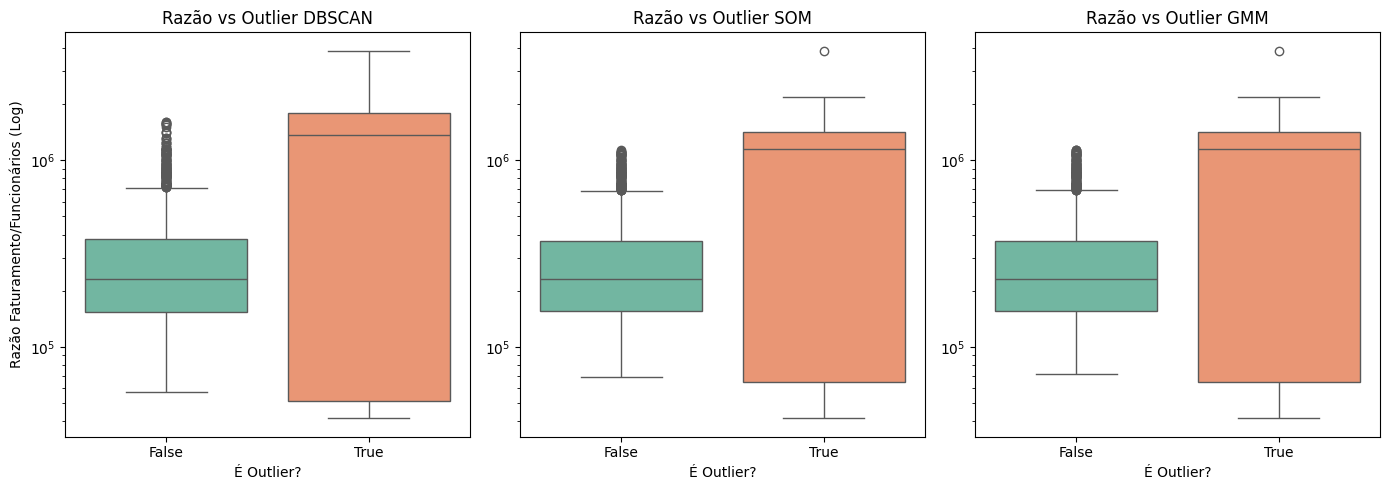

In [14]:
import scipy.stats as stats

# Criar cópias das marcações booleanas de outliers
df_corr = df[[
    'razao_funcionarios_faturamento',
    'is_outlier_dbscan',
    'is_outlier_som',
    'is_outlier_gmm'
]].copy()

print("--- Estatísticas Descritivas da Razão por Tipo de Outlier ---\n")
for col in ['is_outlier_dbscan', 'is_outlier_som', 'is_outlier_gmm']:
    media_inlier = df_corr[df_corr[col] == False]['razao_funcionarios_faturamento'].mean()
    media_outlier = df_corr[df_corr[col] == True]['razao_funcionarios_faturamento'].mean()

    # Correlação bisserial de ponto (para variáveis binárias vs contínuas)
    corr_coef, p_val = stats.pointbiserialr(df_corr[col], df_corr['razao_funcionarios_faturamento'])

    print(f"Modelo: {col.replace('is_outlier_', '').upper()}")
    print(f"  Média Razão nos Inliers:  {media_inlier:,.2f} BRL/Func")
    print(f"  Média Razão nos Outliers: {media_outlier:,.2f} BRL/Func")
    print(f"  Correlação Bisserial:     {corr_coef:.4f} (p-valor: {p_val:.2e})")
    print("-" * 50)

# Visualização gráfica via Boxplot
plt.figure(figsize=(14, 5))

# Derivar uma coluna categórica consolidada para melhor visualização
plt.subplot(1, 3, 1)
sns.boxplot(data=df, x='is_outlier_dbscan', y='razao_funcionarios_faturamento', palette='Set2')
plt.yscale('log')
plt.title('Razão vs Outlier DBSCAN')
plt.xlabel('É Outlier?')
plt.ylabel('Razão Faturamento/Funcionários (Log)')

plt.subplot(1, 3, 2)
sns.boxplot(data=df, x='is_outlier_som', y='razao_funcionarios_faturamento', palette='Set2')
plt.yscale('log')
plt.title('Razão vs Outlier SOM')
plt.xlabel('É Outlier?')
plt.ylabel('')

plt.subplot(1, 3, 3)
sns.boxplot(data=df, x='is_outlier_gmm', y='razao_funcionarios_faturamento', palette='Set2')
plt.yscale('log')
plt.title('Razão vs Outlier GMM')
plt.xlabel('É Outlier?')
plt.ylabel('')

plt.tight_layout()
plt.show()

## 3. Conclusão e Interpretação
A correlação positiva (~0.4) prova que a produtividade/eficiência por funcionário é um dos principais fatores que define se um cliente é classificado como outlier.

Os algoritmos não estão apenas identificando empresas "grandes" de forma isolada, mas estão identificando principalmente empresas com uma assimetria de escala — ou seja, negócios altamente eficientes e produtivos que faturam quantias maciças com estruturas de pessoal muito menores do que o padrão de mercado observado na massa principal de dados.

# Separação de grupos

--- Quantidade de clientes por grupo (GMM) ---
cluster_gmm_3
0    840
2    837
1    323
Name: count, dtype: int64


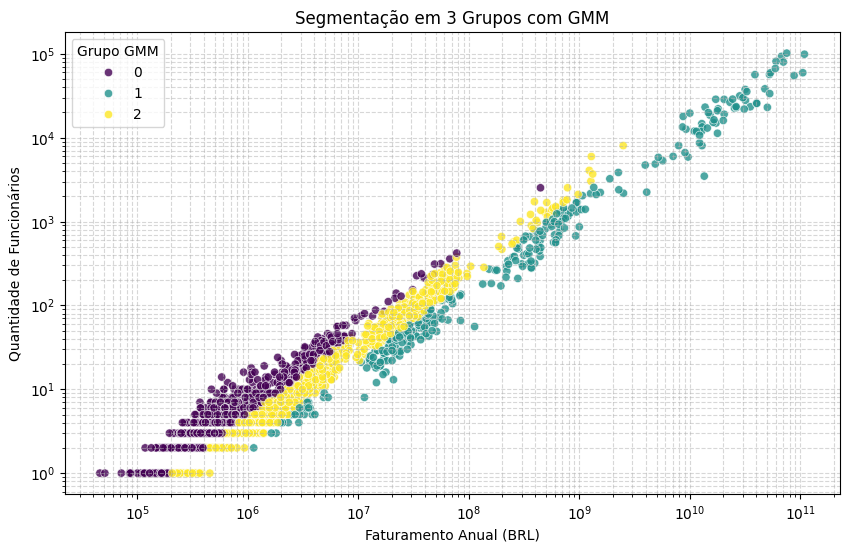

In [15]:
from sklearn.mixture import GaussianMixture

# 1. Configurar e ajustar o GMM para gerar exatamente 3 grupos (componentes)
gmm_3 = GaussianMixture(n_components=3, random_state=42)
df['cluster_gmm_3'] = gmm_3.fit_predict(X_scaled)

# Verificar a distribuição de pontos por grupo
print("--- Quantidade de clientes por grupo (GMM) ---")
print(df['cluster_gmm_3'].value_counts())

# 2. Plotar a dispersão com a separação em 3 grupos
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='faturamento_anual_brl',
    y='qtd_funcionarios',
    hue='cluster_gmm_3',
    palette='viridis',
    alpha=0.8
)

plt.xscale('log')
plt.yscale('log')
plt.title('Segmentação em 3 Grupos com GMM')
plt.xlabel('Faturamento Anual (BRL)')
plt.ylabel('Quantidade de Funcionários')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(title='Grupo GMM')
plt.show()

Aqui, dentro do grupo Inlier, o GMM define 3 grupos distintos. O hachurado em roxo indica o grupo de empresas "menos eficiente". Ele gera menos riqueza utilizando a mesma quantidade de funcionários que os outros grupos. Analogamente, o grupo em amarelo representa empresas com eficiência média, e o grupo verde, por sua vez, eficiência/produtividade alta.